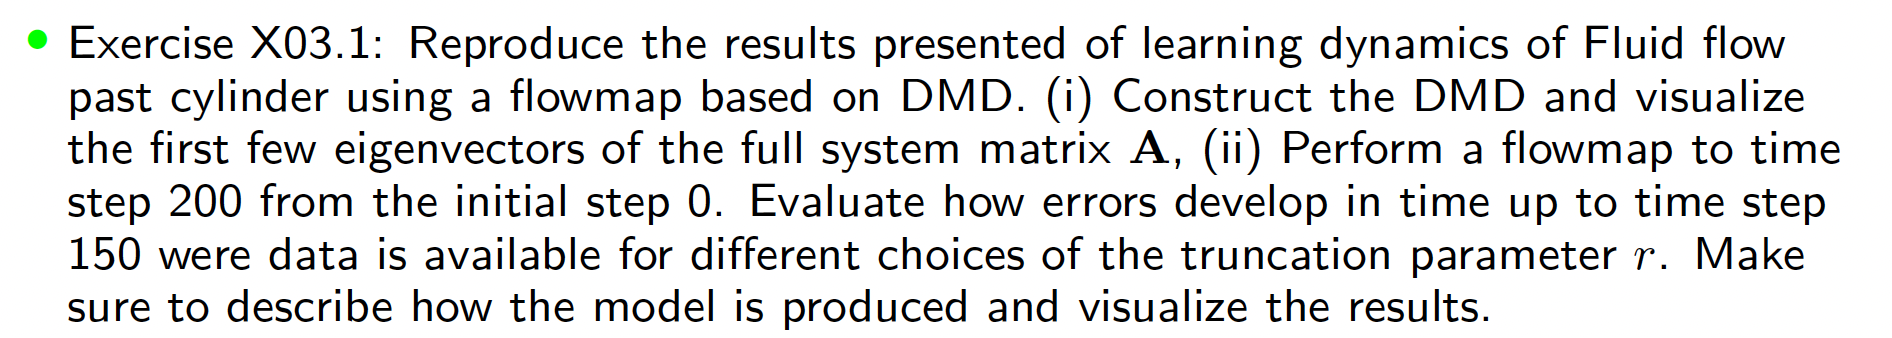

Importing data the same way as done in exercise 1.7

DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude)

In [1]:
# Importing relevant packages
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

In [ ]:
# DATA SET FOR FLUID FLOW PAST A CYLINDER AT RE=100
# Steven L. Brunton
# May 12, 2016
data = sio.loadmat("CODE/CYLINDER_ALL.mat")

In [3]:
# Exporting the relevant data
VORTALL = data["VORTALL"] # Vortices data of dimension (nx*ny,t)
nx = int(data["nx"].item()) # Number of pixels in x direction
ny = int(data["ny"].item()) # Number of pixels in y direction
t = np.shape(VORTALL)[1] # Number of timesteps

In [4]:
# Using the algorithm from page 269 from Data-Driven Science and Engineering for the DMD implementation
def DMD(X, Xprime, r):
    U, sigma, Vh = np.linalg.svd(X, full_matrices=False) # Generating economy SVD
    Sigma = np.diag(sigma) # Setting up the eigenvalues in a diagonal matrice
    V = Vh.conj().T # Recovering the right singular values from the conjugate transpose collected from the SVD
    Ur = U[:, :r] # Extracting the first r left singular vectors
    Sigmar = Sigma[:r, :r] # Extracting the first r eigenvalues
    Vr = V[:, :r] # Extracting the first r right singular vectors
    Atilde = Ur.conj().T @ Xprime @ Vr @ np.linalg.inv(Sigmar)  # Computing the reduced A matrix
    Lambda_vals, W = np.linalg.eig(Atilde)  # Extracting the eigenvalues and eigenvectors and the reduced system matrix
                                            # where the eigenvalues corresponds to that of the full A matrix
    Lambda = np.diag(Lambda_vals) # Setting up the eigenvalues in a diagonal matrix
    Phi = Xprime @ Vr @ np.linalg.inv(Sigmar) @ W # Reconstructing the full A matrix's eigenvectors
    alpha1 = Sigmar @ Vr[0, :].conj().T # Extracting only the first snapshot to compute the mode amplitudes
    b = np.linalg.lstsq(W @ Lambda, alpha1, rcond=None)[0] # Computing the mode amplitudes
    return Phi, Lambda, b


In [5]:
# Setting up the input data and the shifted input data matrices
X = VORTALL[:,:-1]
Xprime = VORTALL[:,1:]
# Generating the DMD using the first 4 modes of the full system matrix
r = 4
Phi, Lambda, b = DMD(X,Xprime,r)


print(Phi.shape) # Ensuring the dimension of Phi is correct (ny*nx, r)

(89351, 4)


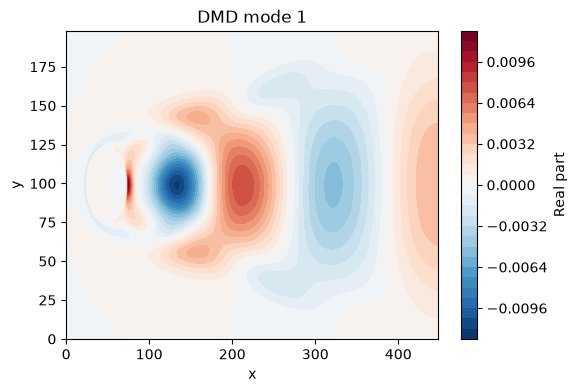

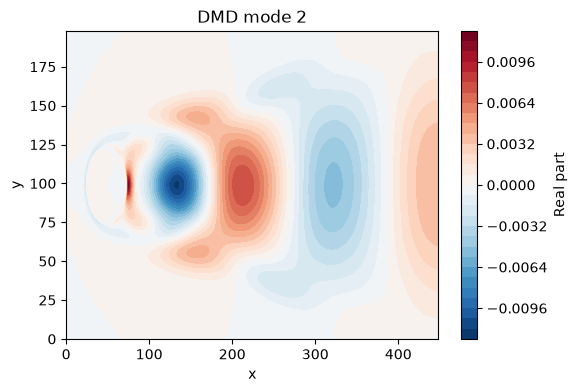

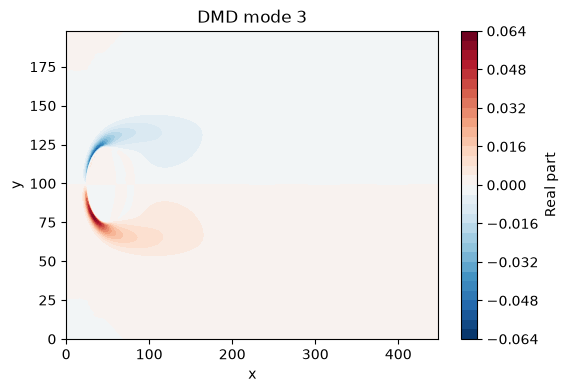

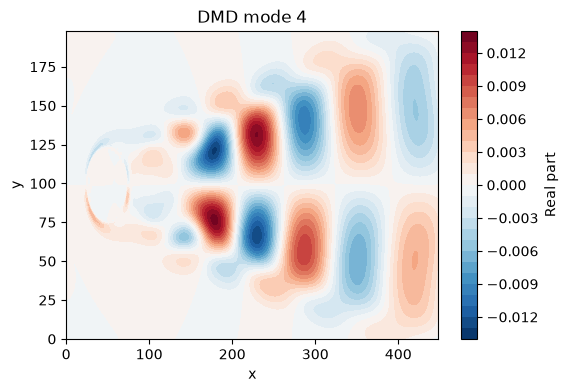

In [6]:
# Plotting the first r eigenvectors of the full system matrix
for j in range(r):
    mode = Phi[:, j].reshape((nx, ny), order="F")

    plt.figure(figsize=(6, 4))
    plt.contourf(mode.real, levels=30, cmap="RdBu_r")
    plt.colorbar(label="Real part")
    plt.title(f"DMD mode {j + 1}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()

From these 4 DMD modes it can be seen that the first two are the same. This is due to them being conjugate partners and their real part are therefore the same (This can be seen below). The third DMD mode seems to describe the inlet and is present at all times with  lambda≈1, which makes sense as the flow is always present here. The fourth DMD shows alternating vortices and with a lambda < 1, this mode decays over time. These 4 DMD modes then show that the predictions will go towards a constant oscillatory behaviour after x amount of time.

These DMD modes can be used to expand the system state by using the DMD eigenvalues (lambda values) and the mode amplitudes (b values). This is done in the forward function below.

In [7]:
print("Eigenvalues:")
for i in range(len(np.diag(Lambda))):
    print(f"{i+1}. {np.diag(Lambda)[i]}")

Eigenvalues:
1. (0.9784212674595534+0.20638354973771492j)
2. (0.9784212674595534-0.20638354973771492j)
3. (1.0000368784758227+0j)
4. (0.9168803409785953+0j)


In [8]:
def forward(X, Xprime, r, n_time):
    """ Input:
        X: Matrix containg snapshots from 0 to t-1 in shape (nx*ny, t-1)
        Xprime: Matrix containg snapshots from 1 to t in shape (nx*ny, t-1)
        r: scalar, the number of eigenvalues to use for truncation
        n_time: scalar, the number of timesteps for expansion
    
        Output: 
        X_pred: The predicted output from the DMD of shape (nx*ny, n_time)
    """
    
    Phi, Lambda, b = DMD(X,Xprime,r)
    Xpred = np.zeros((nx * ny, n_time), dtype=complex)
    for i in range(n_time):
        Xpred[:, i] = Phi @ (np.linalg.matrix_power(Lambda, i) @ b) # DMD Expansion
        
    return Xpred

Now the DMD is used to construct a flowmap to timestep 200 from timestep 0, for 3 different ranks of the SVD

In [9]:
n_time = 200 # timesteps taken
r_values = [2,4,8] # ranks to evaluate
Xpredlist = []
error_list = []
for i in range(len(r_values)):
    Xpred = forward(X, Xprime, r_values[i], n_time)
    Xpredlist.append(Xpred)
    error = (np.linalg.norm(VORTALL - Xpred[:,:t]) ** 2 / np.linalg.norm(VORTALL) ** 2)
    error_list.append(error)
    print(f"The relative error for rank {r_values[i]} is {error}")

The relative error for rank 2 is 0.23959575005237507
The relative error for rank 4 is 0.044753722365474605
The relative error for rank 8 is 0.003481093622814209


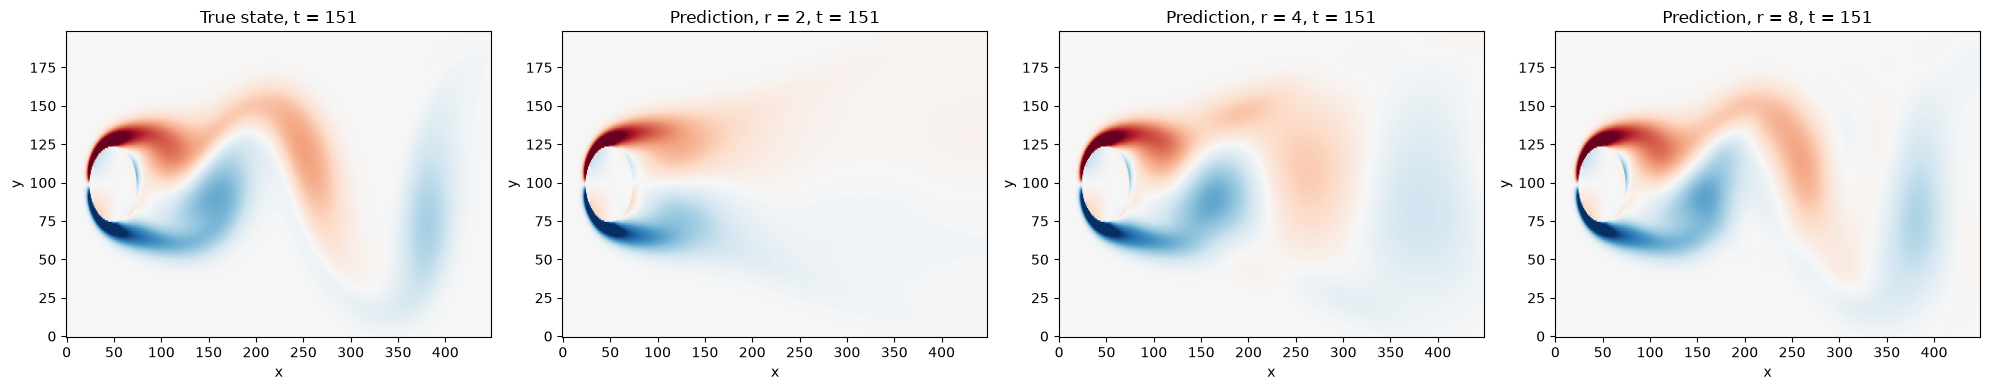

In [10]:
# Comparing the true state at time = 151, last snapshot with the DMD prediction at different ranks
timepoint = t
timepoint_idx = t - 1

fig, axes = plt.subplots(
    1,
    len(r_values) + 1,
    figsize=(5 * (len(r_values) + 1), 4)
)

# True state
true_state = VORTALL[:, timepoint_idx].reshape(ny, nx)

im = axes[0].imshow(
    true_state.T,
    cmap="RdBu",
    origin="lower",
    vmin=-5,
    vmax=5,
    aspect="auto"
)
axes[0].set_title(f"True state, t = {timepoint}")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

# Predicted states
for ax, Xpred, rank in zip(axes[1:], Xpredlist, r_values):
    predicted_state = Xpred[:, timepoint_idx].real.reshape(ny, nx)

    ax.imshow(
        predicted_state.T,
        cmap="RdBu",
        origin="lower",
        vmin=-5,
        vmax=5,
        aspect="auto"
    )
    ax.set_title(f"Prediction, r = {rank}, t = {timepoint}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

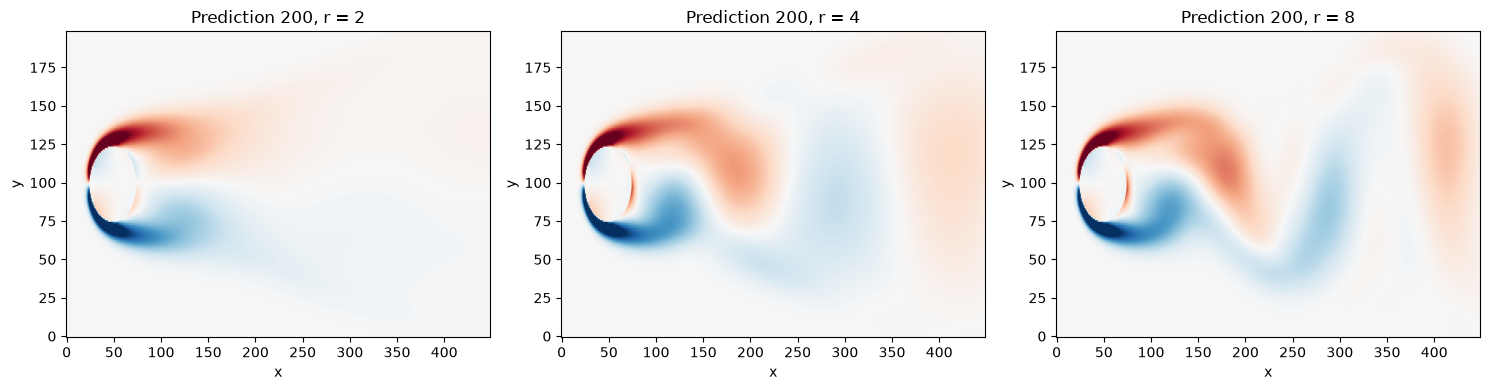

In [11]:
# Comparing the DMD prediction at different ranks for time = 200, the last prediction
prediction_number = 200
prediction_idx = prediction_number - 1

fig, axes = plt.subplots(
    1,
    len(r_values),
    figsize=(5 * len(r_values), 4)
)

for ax, Xpred, rank in zip(axes, Xpredlist, r_values):
    predicted_state = Xpred[:, prediction_idx].real.reshape(ny, nx)

    ax.imshow(
        predicted_state.T,
        cmap="RdBu",
        origin="lower",
        vmin=-5,
        vmax=5,
        aspect="auto"
    )

    ax.set_title(f"Prediction {prediction_number}, r = {rank}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

It is easy to see that with only the first 2 ranks it is impossible to catch the development in time. From t = 150 -> t = 200 there are no difference. This is due to the DMD not having any oscillatory behaviour from complex conjugate pairs in the eigenvectors/eigenvalues (visualized below for r = 2). Whereas, for r = 4 we can see that the predicted oscillatory behaviour from the conjugated DMD modes/values are present. 

When we then increase to r = 8 at t = 150. Here the true state and the truncated is very similar, which can be explained by the higher complexity of the DMD. 

Eigenvalues:
1. 0.9999488509883852
2. 0.9778799298166375


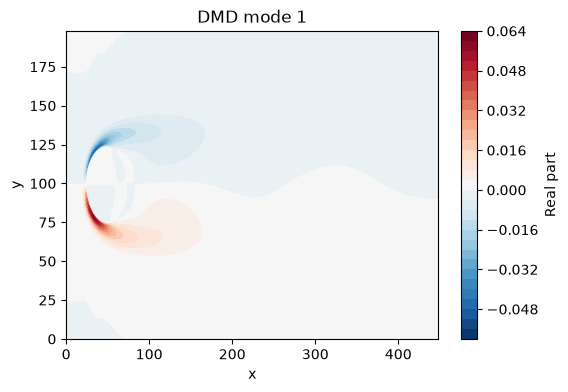

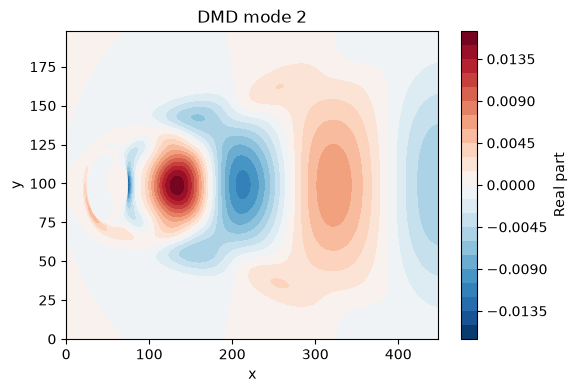

In [12]:
r = 2
Phi, Lambda, b = DMD(X,Xprime,r)
print("Eigenvalues:")
for i in range(len(np.diag(Lambda))):
    print(f"{i+1}. {np.diag(Lambda)[i]}")


for j in range(r):
    mode = Phi[:, j].reshape((nx, ny), order="F")

    plt.figure(figsize=(6, 4))
    plt.contourf(mode.real, levels=30, cmap="RdBu_r")
    plt.colorbar(label="Real part")
    plt.title(f"DMD mode {j + 1}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()
